# Faster R-CNN v2: análisis en test

Analizamos el baseline (`run_name="baseline"`, mejor época en validación) sobre el test. No repetimos la inferencia: leemos las predicciones que guarda

```bash
python scripts/evaluation/evaluate_faster_rcnn.py --split val
python scripts/evaluation/evaluate_faster_rcnn.py --split test
```

en `results/metrics/fasterrcnn_v2/baseline/`. Las figuras se guardan en `results/figures/fasterrcnn_v2/baseline/` para la presentación.

Todo lo que se decide (el umbral de confianza para la matriz de confusión y los ejemplos) se elige en **validación**; el test solo se mide.

Las funciones están en `src/parasite_detection/analysis.py` y solo necesitan predicciones en formato COCO, así que sirven igual para YOLOv10-S.

In [1]:
import json

import pandas as pd
from IPython.display import display

from parasite_detection import analysis as an
from parasite_detection.paths import DEDUP_DATA, RESULTS

MODEL, RUN = "fasterrcnn_v2", "baseline"
metrics_dir = RESULTS / "metrics" / MODEL / RUN
figures_dir = RESULTS / "figures" / MODEL / RUN
image_dir = DEDUP_DATA / "images" / "test"

an.set_style()
coco = {split: an.load_coco(DEDUP_DATA, split) for split in ("val", "test")}
predictions = {split: an.load_predictions(metrics_dir / f"{split}_predictions.json") for split in ("val", "test")}
metrics = {split: json.loads((metrics_dir / f"{split}_metrics.json").read_text()) for split in ("val", "test")}
per_class = {split: pd.read_csv(metrics_dir / f"{split}_per_class.csv") for split in ("val", "test")}
history = pd.read_csv(metrics_dir / "training.csv")

## 1. Métricas globales

Métricas COCO (`pycocotools`) con todas las detecciones de confianza ≥ 0.05, como máximo 100 por imagen. El tiempo es la llamada al modelo con lote 1, sin las 3 primeras imágenes de calentamiento.

In [2]:
rows = {
    "mAP@[.5:.95]": "map", "mAP@0.5": "map50", "mAP@0.75": "map75",
    "AP small": "map_small", "AP medium": "map_medium", "AP large": "map_large",
    "AR@1": "mar1", "AR@10": "mar10", "AR@100": "mar100",
}
summary = pd.DataFrame({split: {name: metrics[split][key] for name, key in rows.items()} for split in ("val", "test")})
summary.loc["ms / imagen"] = [metrics[s]["inference"]["mean_ms"] for s in ("val", "test")]
summary.loc["imágenes"] = [metrics[s]["images"] for s in ("val", "test")]
summary.loc["objetos"] = [metrics[s]["objects"] for s in ("val", "test")]
print("Inferencia:", metrics["test"]["inference"]["device"], "|", metrics["test"]["inference"]["hardware"],
      "|", metrics["test"]["inference"]["torch_threads"], "hilos")
summary.round(3)

Inferencia: cpu | Intel64 Family 6 Model 186 Stepping 2, GenuineIntel | 10 hilos


,val,test
mAP@[.5:.95],0.663,0.623
mAP@0.5,0.809,0.784
mAP@0.75,0.791,0.745
AP small,0.000,0.247
AP medium,0.425,0.428
AP large,0.722,0.691
AR@1,0.471,0.407
AR@10,0.741,0.709
AR@100,0.766,0.749
ms / imagen,2256.140,2061.525


## 2. Curvas de entrenamiento

La línea discontinua marca la época con mayor mAP@[.5:.95] en validación, que es el checkpoint que evaluamos.

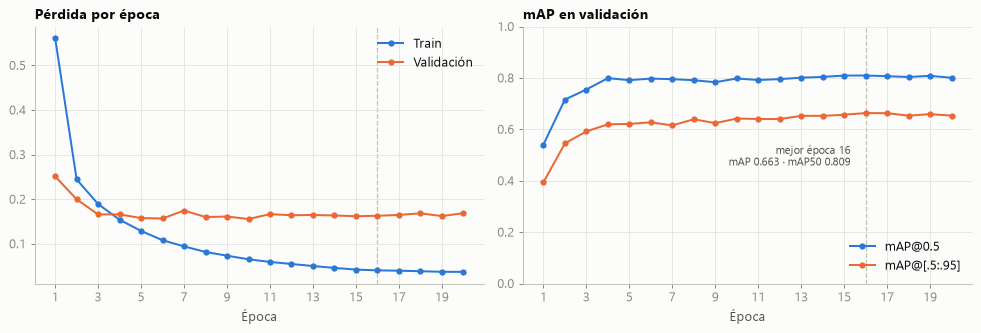

In [3]:
an.plot_training(history, figures_dir / "training_curves.png");

## 3. Curvas PR por especie en test

Una curva por especie a IoU 0.5 y 0.75 (los 101 puntos de recall de COCO). Cuando las dos curvas casi coinciden, las cajas están bien ajustadas: lo que falta es detectar o clasificar mejor.

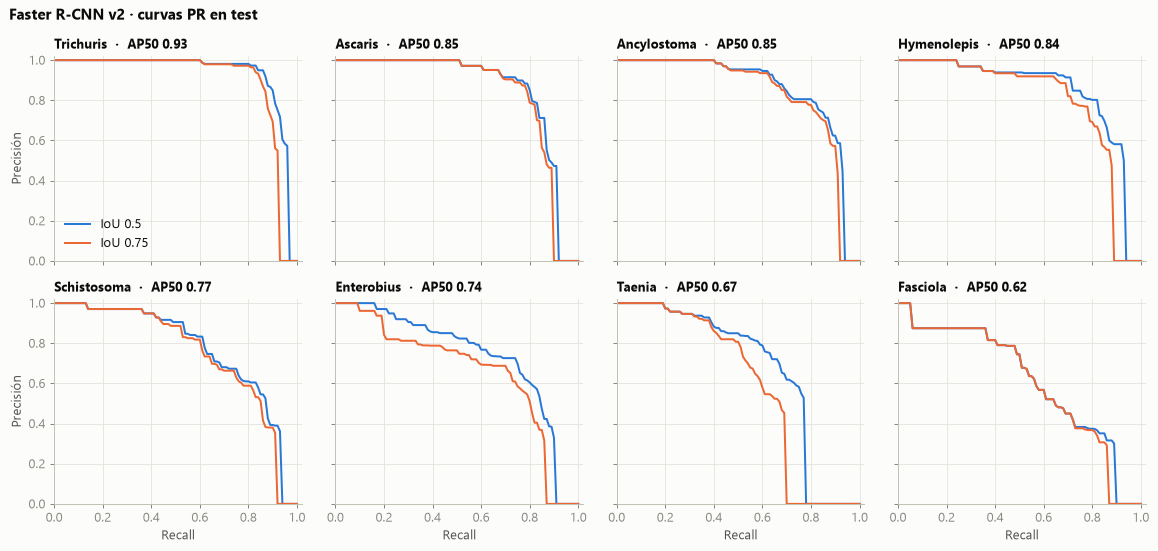

In [4]:
an.plot_pr_curves(pd.read_csv(metrics_dir / "test_pr_curves.csv"), per_class["test"],
                  title="Faster R-CNN v2 · curvas PR en test", path=figures_dir / "pr_curves_test.png");

## 4. AP por especie: validación frente a test

,category_id,name,objects_val,ap_val,ap50_val,objects_test,ap_test,ap50_test
0,1,Ancylostoma Spp,43,0.595,0.675,140,0.673,0.852
1,2,Ascaris Lumbricoides,49,0.681,0.812,115,0.733,0.853
2,3,Enterobius Vermicularis,106,0.639,0.832,154,0.547,0.737
3,4,Fasciola Hepatica,40,0.611,0.735,76,0.512,0.617
4,5,Hymenolepis,43,0.813,0.941,89,0.686,0.843
5,6,Schistosoma,66,0.633,0.791,90,0.624,0.773
6,7,Taenia Sp,53,0.643,0.832,168,0.478,0.670
7,8,Trichuris Trichiura,60,0.690,0.857,131,0.732,0.930


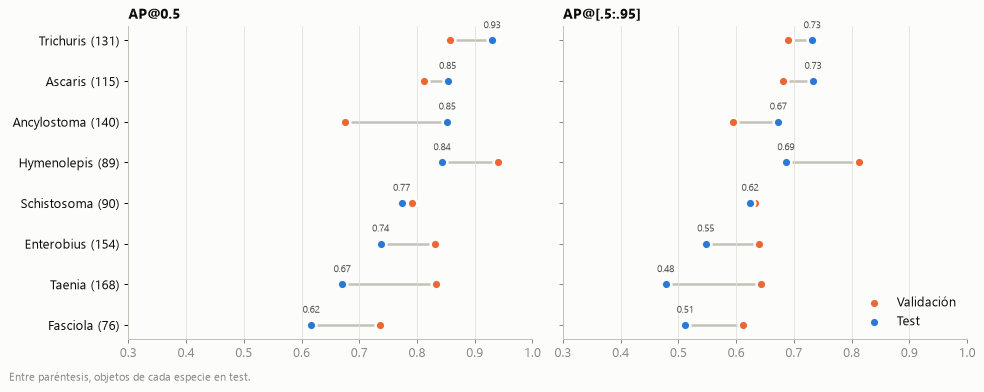

In [5]:
an.plot_ap_val_test(per_class["val"], per_class["test"], path=figures_dir / "ap_per_class_val_test.png")
per_class["val"].merge(per_class["test"], on=["category_id", "name"], suffixes=("_val", "_test")).round(3)

## 5. Umbral de confianza

El mAP no necesita umbral, pero la matriz de confusión y los ejemplos sí. Elegimos el umbral con mayor F1 en **validación** (emparejamiento por clase con IoU ≥ 0.5) y lo aplicamos tal cual a test.

Umbral elegido en validación: 0.90


,threshold,tp,fp,fn,precision,recall,f1
0,0.05,418,605,42,0.409,0.909,0.564
1,0.10,408,434,52,0.485,0.887,0.627
2,0.15,399,357,61,0.528,0.867,0.656
3,0.20,397,314,63,0.558,0.863,0.678
4,0.25,392,273,68,0.589,0.852,0.697
5,0.30,388,249,72,0.609,0.843,0.707
6,0.35,384,221,76,0.635,0.835,0.721
7,0.40,379,204,81,0.650,0.824,0.727
8,0.45,376,187,84,0.668,0.817,0.735
9,0.50,375,167,85,0.692,0.815,0.749


Mismo umbral en test:


,threshold,tp,fp,fn,precision,recall,f1
0,0.9,651,136,312,0.827,0.676,0.744


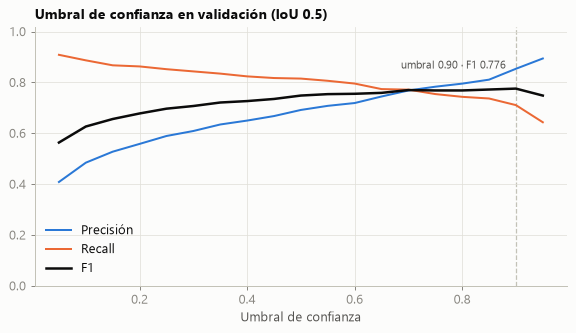

In [6]:
sweep = an.threshold_sweep(coco["val"], predictions["val"])
threshold = float(sweep.loc[sweep["f1"].idxmax(), "threshold"])
an.plot_threshold_sweep(sweep, threshold, path=figures_dir / "threshold_val.png")
print(f"Umbral elegido en validación: {threshold:.2f}")
display(sweep.round(3))
print("Mismo umbral en test:")
an.threshold_sweep(coco["test"], predictions["test"], thresholds=[threshold]).round(3)

## 6. Matriz de confusión en test

Cada detección con confianza ≥ umbral se empareja, de mayor a menor confianza, con la caja real libre de mayor IoU (≥ 0.5) de **cualquier** clase. Así se ve con qué especie se confunde cada una. La fila *Fondo* son detecciones donde no hay ningún huevo; la columna *No detectado*, huevos sin ninguna detección. El color está normalizado por fila.

,Ancylostoma,Ascaris,Enterobius,Fasciola,Hymenolepis,Schistosoma,Taenia,Trichuris,No detectado
Ancylostoma,90,0,0,6,0,1,0,0,43
Ascaris,2,78,0,1,0,1,1,0,32
Enterobius,0,0,113,2,0,0,0,0,39
Fasciola,2,2,2,43,0,2,0,3,22
Hymenolepis,1,0,0,0,63,0,4,1,20
Schistosoma,0,1,0,5,0,55,0,1,28
Taenia,0,1,0,0,4,0,96,0,67
Trichuris,1,1,6,2,0,0,0,113,8
Fondo,2,1,35,13,2,9,18,3,0


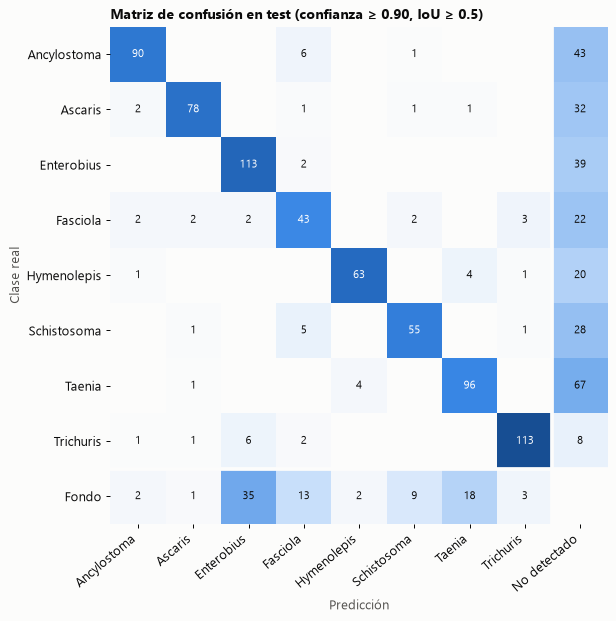

In [7]:
confusion = an.confusion_matrix(coco["test"], predictions["test"], threshold)
an.plot_confusion(confusion, threshold, path=figures_dir / "confusion_matrix_test.png")
confusion

## 7. ¿Dónde se pierde el mAP? Errores tipo TIDE

Desglose simplificado de TIDE de `mapviz` (sección 9 del notebook de la práctica), con todas las detecciones y a IoU 0.5. Cada detección errónea se asigna a un tipo:

| tipo | definición |
|---|---|
| clasificación | IoU ≥ 0.5 con un huevo de otra especie |
| localización | IoU entre 0.1 y 0.5 con algún huevo |
| duplicado | IoU ≥ 0.5 con un huevo que ya tiene una detección de mayor confianza |
| fondo | IoU < 0.1 con todos los huevos |
| no detectado | huevo sin ninguna detección que lo explique |

Un oráculo corrige solo un tipo, se recalcula el mAP@0.5 y se anota la ganancia. Importa la ganancia, no el número de casos: un error de confianza 0.06 casi no resta AP.

mAP@0.5 de mapviz: 0.7844 | pycocotools: 0.7844


,error,key,count,delta_map50
0,Clasificación,cls,721,0.0875
1,Localización,loc,44,0.0035
2,Duplicado,dup,0,0.0000
3,Fondo,bg,598,0.0490
4,No detectado,miss,51,0.0196


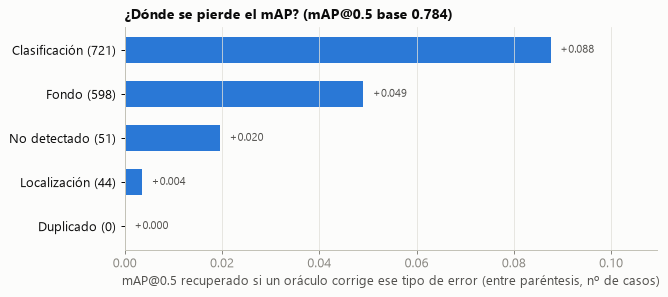

In [8]:
breakdown, errors_table = an.error_breakdown(coco["test"], predictions["test"])
an.plot_error_breakdown(errors_table, breakdown["base"], path=figures_dir / "error_breakdown_test.png")
print(f"mAP@0.5 de mapviz: {breakdown['base']:.4f} | pycocotools: {metrics['test']['map50']:.4f}")
errors_table.round(4)

## 8. Ejemplos cualitativos

Con el umbral de validación. Verde: detección correcta; rojo: detección errónea con su tipo de error; ámbar discontinuo: huevo no detectado.

### 8.1 Una detección correcta por especie

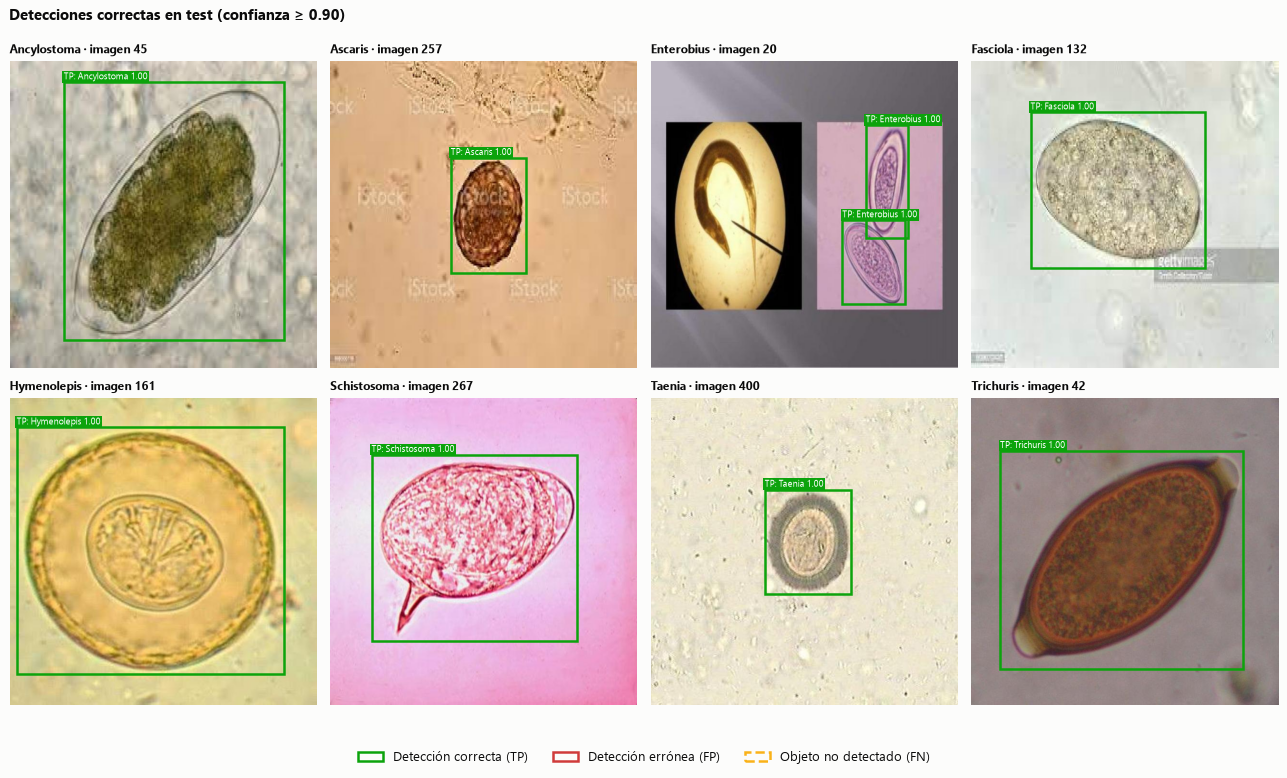

In [9]:
per_image = an.image_errors(coco["test"], predictions["test"], threshold)
correct_ids, correct_names = an.pick_correct_examples(coco["test"], per_image)
an.plot_examples(coco["test"], image_dir, per_image, correct_ids,
                 [f"{n} · imagen {i}" for n, i in zip(correct_names, correct_ids)],
                 suptitle=f"Detecciones correctas en test (confianza ≥ {threshold:.2f})",
                 path=figures_dir / "examples_correct_test.jpg");

### 8.2 Un ejemplo de cada tipo de error

Para cada tipo, el error de mayor confianza, ampliado (para *No detectado*, el huevo más grande sin ninguna detección cerca).

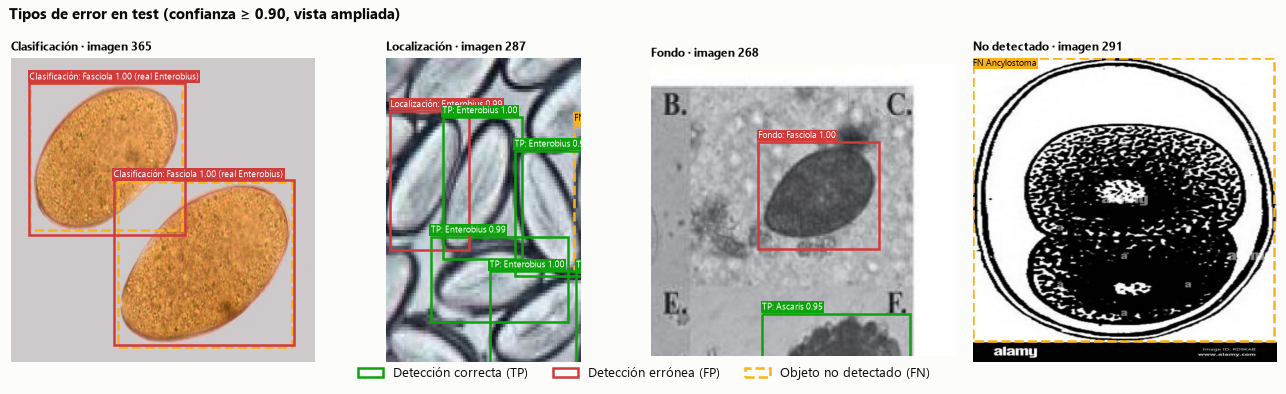

In [10]:
error_ids, error_keys, error_boxes = an.pick_error_examples(per_image)
an.plot_examples(coco["test"], image_dir, per_image, error_ids,
                 [f"{an.ERROR_LABELS[k]} · imagen {i}" for k, i in zip(error_keys, error_ids)],
                 ncols=len(error_ids), focus=error_boxes,
                 suptitle=f"Tipos de error en test (confianza ≥ {threshold:.2f}, vista ampliada)",
                 path=figures_dir / "examples_errors_test.jpg");

### 8.3 Imágenes con más errores

En las imágenes con muchas cajas se omiten los textos y el título da el recuento. La tabla cuenta, por especie, los huevos sin detección correcta (incluye los que tienen una detección de otra clase o mal ajustada) y si se concentran en pocas imágenes.

,especie,no_detectados,imagenes,en_top3,top3_imagenes
6,Taenia,72,20,42,"193 (26), 126 (12), 237 (4)"
0,Ancylostoma,50,26,19,"47 (11), 238 (4), 298 (4)"
2,Enterobius,41,18,19,"90 (10), 77 (5), 287 (4)"
1,Ascaris,37,25,13,"16 (6), 240 (5), 34 (2)"
5,Schistosoma,35,22,12,"144 (5), 86 (4), 5 (3)"
3,Fasciola,33,18,13,"141 (5), 12 (4), 183 (4)"
4,Hymenolepis,26,15,13,"82 (8), 99 (3), 49 (2)"
7,Trichuris,18,14,7,"216 (3), 124 (3), 85 (1)"


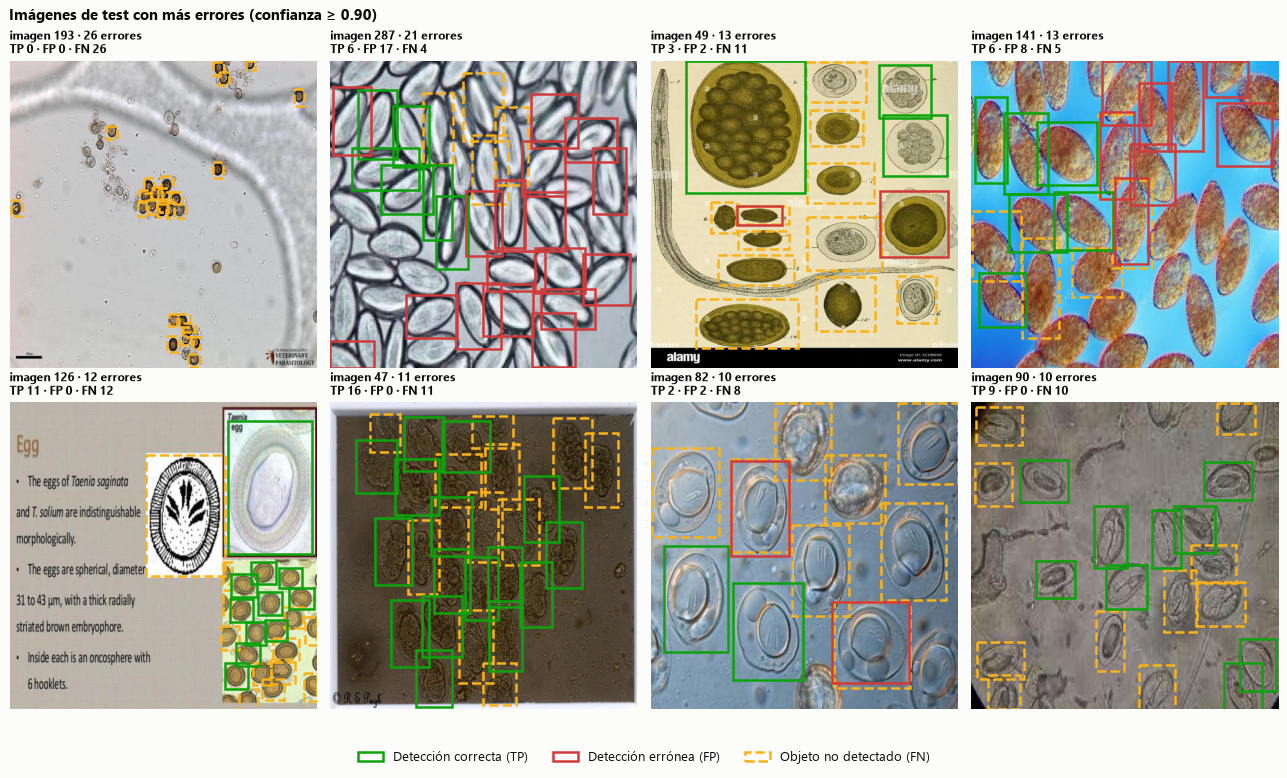

In [11]:
worst_ids, counts = an.worst_images(per_image, n=8)
an.plot_examples(coco["test"], image_dir, per_image, worst_ids,
                 [f"imagen {i} · {counts[i]} errores" for i in worst_ids],
                 suptitle=f"Imágenes de test con más errores (confianza ≥ {threshold:.2f})",
                 path=figures_dir / "examples_worst_test.jpg")
an.missed_by_class(coco["test"], per_image)


## 9. Observaciones (baseline, 25-11-2026)

Lo que muestran las cifras y figuras de arriba; las interpretaciones marcadas como hipótesis están por comprobar.

- **Test por debajo de validación**: mAP@[.5:.95] 0.623 frente a 0.663 y mAP@0.5 0.784 frente a 0.809. Es esperable porque la época se eligió con validación; el train está deduplicado frente a test, así que el resultado no está inflado por fuga.
- **La localización casi no penaliza**: mAP@0.75 (0.745) está cerca de mAP@0.5 (0.784) y, en el desglose TIDE, corregir la localización solo daría +0.004. No hay duplicados (el NMS por clase los elimina).
- **Lo que más cuesta es la clasificación** (+0.088 de mAP@0.5 si se corrigiera) y después las **detecciones de fondo** (+0.049). Los huevos que ninguna detección toca pesan poco (+0.020): el modelo casi siempre encuentra el huevo, pero a veces con la especie equivocada o con poca confianza.
- **La caída de Taenia se concentra en pocas imágenes**: de sus 72 huevos sin detección correcta, 38 están en dos imágenes, la 193 (26 huevos muy pequeños y agrupados, ninguno detectado) y la 126 (un collage de diapositiva con texto). No parece un problema general de la especie, sino de **objetos pequeños** y de **imágenes que no son microscopía**.
- **Varias de las peores imágenes son ilustraciones, collages o capturas de libro** (49, 126, 268, 291). Esto conecta con el etiquetado por tipo de imagen del train: tiene sentido analizar el error por tipo.
- *Hipótesis*: en las imágenes muy pobladas (287, 141) hay detecciones de *Fondo* con confianza ≥ 0.9 sobre lo que parecen huevos reales sin anotar. Si es así, parte de esos falsos positivos son anotaciones incompletas y no errores del modelo. Conviene revisarlas a mano.
- *Hipótesis*: en la imagen 365 los dos huevos están anotados como *Enterobius* y el modelo dice *Fasciola* con confianza 1.00. Hay que revisar la anotación antes de contarlo como error del modelo.
- **Umbral**: en validación, el F1 es casi plano entre 0.65 y 0.90 (0.76–0.78). El máximo está en 0.90, lo que indica que el modelo da confianzas muy altas también a muchos falsos positivos.
- **Inferencia**: unos 2.1 s por imagen en CPU (Intel, 10 hilos, lote 1). Para comparar con YOLO hay que medirlo en la misma máquina.

Líneas de mejora que salen de aquí: más resolución de entrada o anclas más pequeñas para los huevos pequeños; aumento de color y tinción para la confusión entre especies; analizar o filtrar por tipo de imagen; y revisar las anotaciones dudosas.
